# Spatial Distance-Weighted Cell–Cell Interaction Scoring

Before running this section, download the CellChatDB database file (CellChatDB.human.rda) from the CellChat GitHub data directory (https://github.com/jinworks/CellChat/data), convert it to a CSV file in the R environment, and save it as CellChatDB.csv.

In [ ]:
import pandas as pd
import numpy as np
import cupy as cp
import tqdm
from scipy.spatial import cKDTree
import os
import pickle
import scanpy as sc
from Xenium_5K_IPF_constants import WORK_PATH

# Option
sc.settings.verbosity = 3

# Constant Declaration
rad = 300.0  # Define cells within this radius as neighborhood
sigma = 150.0  # Gaussian sigma

In [ ]:
# Select interest cell group

interest_label = "Epithelial" 

In [ ]:
interaction_dir = f"{WORK_PATH}Interaction/interaction_scores_{interest_label}"
os.makedirs(interaction_dir, exist_ok=True)

In [ ]:
adata = sc.read_h5ad(f"{WORK_PATH}AnnData/spatial_merged.h5ad")

In [ ]:
celltype_csv = pd.read_csv(f"{WORK_PATH}CSV/013_merge_type.csv", index_col="cell_id")
adata = adata[celltype_csv.index].copy()
adata.obs = pd.merge(adata.obs, celltype_csv[["cell_type", "subtype"]], left_index=True, right_index=True)

In [ ]:
# library size normalization
sc.pp.normalize_total(adata, target_sum=1e4)

In [ ]:
# Loading and filtering CellChat database
cellchat_db = pd.read_csv(f"{WORK_PATH}CellchatDB/CellChatDB.csv")
cellchat_db_ss = cellchat_db[cellchat_db["annotation"] == "Secreted Signaling"].copy()

cellchat_db_ss = pd.DataFrame({
    "pathway_name": cellchat_db_ss["pathway_name"].values,
    "ligand": cellchat_db_ss["ligand"].values,
    "receptor": cellchat_db_ss["receptor"].values,
    "lig_list": cellchat_db_ss["ligand.symbol"].str.split(",").apply(lambda L: [s.strip() for s in L]).values,
    "rec_list": cellchat_db_ss["receptor.symbol"].str.split(",").apply(lambda L: [s.strip() for s in L]).values,
})

cellchat_db_ss["gene_list"] = cellchat_db_ss.apply(
    lambda r: sorted(set(r["lig_list"] + r["rec_list"])), 
    axis=1
)

cellchat_db_ss["interaction_name"] = cellchat_db_ss["ligand"] + " - " + cellchat_db_ss["receptor"]

In [ ]:
# Sort genes
cellchat_all_genes=set(cellchat_db_ss["gene_list"].sum())
sorted_genes = sorted(set(adata.var_names) & set(cellchat_all_genes))
print(f"{len(sorted_genes)} genes extracted")

In [ ]:
# Re-filtering CellChat data
valid_ix_cellchat = [i for i, gset in enumerate(cellchat_db_ss["gene_list"]) if set(gset).issubset(sorted_genes)]
cellchat_db_f = cellchat_db_ss.iloc[valid_ix_cellchat].reset_index(drop=True)
cellchat_db_f.to_pickle(f"{WORK_PATH}Interaction/interaction_data.pkl")

expr = adata[:, sorted_genes].to_df()
gene_to_col = {g: i for i, g in enumerate(expr.columns)} 

In [ ]:
# for presenting data
cellchat_db_csv = cellchat_db_f[["pathway_name", "interaction_name", "ligand", "receptor"]].copy()
cellchat_db_csv.loc[:, "lig_list"] = cellchat_db_f["lig_list"].apply(",".join)
cellchat_db_csv.loc[:, "rec_list"] = cellchat_db_f["rec_list"].apply(",".join)
cellchat_db_csv.to_csv(f"{WORK_PATH}CSV/031_interaction_data.csv", index=False)  

In [ ]:
# create edges of the interest cells
coords = adata.obsm["spatial"]
tree = cKDTree(coords)

is_interest = (adata.obs["cell_type"].values == interest_label) 
interest_idx = np.where(is_interest)[0]

In [ ]:
# Get cell coordinates within R mm of each interest cell (Neighbor cells).
neighbor_from_interest = tree.query_ball_point(coords[interest_idx], r=rad)

# Edge sets
int_to_nei_edges = []  # list of tuples (e, np.array(nei_interests))
for n, neis in enumerate(neighbor_from_interest):
    if not neis:
        continue
    e = interest_idx[n]
    neis = [m for m in neis if m != e]  # int ≠ nei
    if neis:
        int_to_nei_edges.append((e, np.array(neis, dtype=int)))

# Convert to cupy for GPU
expr_cp   = cp.asarray(expr.values, dtype=cp.float32)
coords_cp = cp.asarray(coords, dtype=cp.float32)

In [ ]:
del coords, tree, expr, neighbor_from_interest, adata

In [ ]:
# Geometric mean function definition
def geometric_mean(expr_g: cp.ndarray, col_ids: list[int]) -> cp.ndarray:
    if not col_ids:
        return cp.zeros(expr_g.shape[0], dtype=cp.float32)
    vals = expr_g[:, col_ids]
    return cp.exp(cp.mean(cp.log(vals), axis=1)).astype(cp.float32)

In [ ]:
# Calculate weights in advance (Gaussian filter)
edge_list = []
w_list    = []
coeff = -1.0 / (2.0 * sigma * sigma)  # coefficient
for e, nei_arr in int_to_nei_edges: 
    nei_cp = cp.asarray(nei_arr, dtype=cp.int32)
    d2     = cp.sum((coords_cp[nei_cp] - coords_cp[e])**2, axis=1)
    w      = cp.exp(coeff * d2).astype(cp.float32)
    edge_list.append((e, nei_cp))  # interest cell index and neighbor indices
    w_list.append(w)               # weights for the intererst–neighbor pairs

In [ ]:
for _, row in tqdm.tqdm(cellchat_db_f.iterrows(), total=len(cellchat_db_f)):

    lig_idx = [gene_to_col[g] for g in row["lig_list"] if g in gene_to_col]
    rec_idx = [gene_to_col[g] for g in row["rec_list"] if g in gene_to_col]
    
    if not lig_idx or not rec_idx:
        continue

    geo_lig_all = geometric_mean(expr_cp, lig_idx)  
    geo_rec_all = geometric_mean(expr_cp, rec_idx) 

    scores_nei_to_int = {}
    scores_int_to_nei = {}

    for (it, ni), w in zip(edge_list, w_list):
        s_nei2int = geo_lig_all[ni] * geo_rec_all[it] * w
        m1 = s_nei2int > 0
        if m1.any().item():  
            idx = cp.asnumpy(ni[m1])
            val = cp.asnumpy(s_nei2int[m1])
            scores_nei_to_int.update({(int(j), int(it)): float(s) for j, s in zip(idx, val)})

        s_int2nei = geo_lig_all[it] * geo_rec_all[ni] * w
        m2 = s_int2nei > 0
        if m2.any().item(): 
            idx = cp.asnumpy(ni[m2])
            val = cp.asnumpy(s_int2nei[m2])
            scores_int_to_nei.update({(int(it), int(j)): float(s) for j, s in zip(idx, val)})

    if scores_nei_to_int or scores_int_to_nei:
        with open(os.path.join(interaction_dir, f"{row["interaction_name"]}.pkl"), "wb") as f:
            pickle.dump({"nei_to_int": scores_nei_to_int, "int_to_nei": scores_int_to_nei}, f)

# Aggregation of Cell–Cell Interaction by Subtype

In [ ]:
import pandas as pd
import numpy as np
import tqdm
import os
import pickle
import glob
from Xenium_5K_IPF_constants import ALL_SUBTYPE_LIST, WORK_PATH

# Constant Declaration
B   = 10000  # number of iterations for a permutation test
rng = np.random.default_rng(42)  # random seed

In [ ]:
# Select interest cell group

interest_label = "Epithelial" 

In [ ]:
# Loading meta data
meta = pd.read_csv(f"{WORK_PATH}CSV/013_merge_type.csv", index_col="cell_id")

# Data unification
cell_type_arr = meta["cell_type"].astype(str).values
subtype_arr   = meta["subtype"].astype(str).values

# subtypes of the interest cell group
interest_subtype= meta.loc[meta["cell_type"]==interest_label, "subtype"].unique()
int_subtype_list = [a for a in ALL_SUBTYPE_LIST if a in interest_subtype]

In [ ]:
# interest cell IDs
is_interest = (cell_type_arr == interest_label)
interest_idx = np.where(is_interest)[0] 

# Linking subtypes to IDs
all_subtypes  = np.unique(subtype_arr)
subtype_to_id = {s:i for i,s in enumerate(all_subtypes)}
id_to_subtype = {i:s for s,i in subtype_to_id.items()}
subtype_ids   = np.array([subtype_to_id[s] for s in subtype_arr], dtype=np.int32)

# counts of interest cells
counts_target  = pd.Series(subtype_arr[interest_idx]).value_counts().to_dict() 

In [ ]:
def aggregate_and_permute(edge_dict: dict, direction: str, pathway_name: str) -> list:
    if not edge_dict:
        return []

    if direction == "nei_to_int":
        row_names = ALL_SUBTYPE_LIST
        col_names = int_subtype_list
    elif direction == "int_to_nei":
        row_names = int_subtype_list
        col_names = ALL_SUBTYPE_LIST

    R, C = len(row_names), len(col_names)

    row_global_ids = np.array([subtype_to_id[n] for n in row_names], dtype=np.int32)
    col_global_ids = np.array([subtype_to_id[n] for n in col_names], dtype=np.int32)

    # global id -> local index
    nS = len(id_to_subtype)
    row_map = -np.ones(nS, dtype=np.int32); row_map[row_global_ids] = np.arange(R, dtype=np.int32)
    col_map = -np.ones(nS, dtype=np.int32); col_map[col_global_ids] = np.arange(C, dtype=np.int32)

    # Edge arraying
    items  = list(edge_dict.items())  # ((sender_idx, reciever_idx), scores)
    pairs  = np.array([k for k, _ in items], dtype=object)  # (sender_idx, reciever_idx)
    scores = np.array([v for _, v in items], dtype=np.float64) # scores
    src_idx = pairs[:,0].astype(int)  # sender_idx
    tgt_idx = pairs[:,1].astype(int)  # reciever_idx

    # global subtype id
    if direction == "nei_to_int":
        row_src_global = subtype_ids[src_idx]   # row = neighbor
        col_tgt_global = subtype_ids[tgt_idx]   # column = interest
        # denominator: interest (tgt)
        denom = np.array([counts_target.get(id_to_subtype[sid], 0) for sid in col_tgt_global], dtype=np.int64)
        # Shuffle Target = neighbor（src）
        nei_idx_for_shuffle = src_idx
    else:  # 'int_to_nei'
        row_src_global = subtype_ids[src_idx]   # row = interest
        col_tgt_global = subtype_ids[tgt_idx]   # column = neighbor
        # denominator: interest (src)
        denom = np.array([counts_target.get(id_to_subtype[sid], 0) for sid in row_src_global], dtype=np.int64)
        # Shuffle Target = neighbor（tgt）
        nei_idx_for_shuffle = tgt_idx

    # Global → fixed grid local indices
    row_idx = row_map[row_src_global]
    col_idx = col_map[col_tgt_global]

    # Validate egdes
    valid = (row_idx >= 0) & (col_idx >= 0) & (denom > 0)
    if not np.any(valid):
        return None
    row_idx = row_idx[valid]
    col_idx = col_idx[valid]
    scores  = scores[valid]
    denom   = denom[valid]
    nei_idx_for_shuffle = nei_idx_for_shuffle[valid]
    
   # Observation matrix（fixed size R x C）----
    obs_mat = np.zeros((R, C), dtype=np.float64)
    np.add.at(obs_mat, (row_idx, col_idx), scores / denom)

    # neighbor-only permutation
    # unique neighbor cells, inverse index
    unique_nei, nei_pos_per_edge = np.unique(nei_idx_for_shuffle, return_inverse=True) # nei_pos_per_edge: 各エッジの neighbor が unique_nei のどの位置か
    nei_cell_sub_global = subtype_ids[unique_nei]  # global subtype IDs of neighbors

    ge_counts = np.zeros((R, C), dtype=np.int32)

    # Permutation test
    for _ in range(B):
        shuf = rng.permutation(nei_cell_sub_global)      # Permute global subtype IDs of neighbors
        nei_perm_global = shuf[nei_pos_per_edge]         # The replaced global subtype ID of each edge

        perm_mat = np.zeros((R, C), dtype=np.float64)
        if direction == "nei_to_int":
            row_perm = row_map[nei_perm_global]          # permute rows（neighbor）
            np.add.at(perm_mat, (row_perm, col_idx), scores / denom)
        else:  # 'tar_to_nei'
            col_perm = col_map[nei_perm_global]          # permute columns（neighbor）
            np.add.at(perm_mat, (row_idx, col_perm), scores / denom)

        ge_counts += (perm_mat >= obs_mat)

    # +1 correction
    pvals = (ge_counts + 1) / (B + 1)

    # Output
    rows_out = []
    for i in range(R):
        for j in range(C):
            if obs_mat[i, j] == 0 and ge_counts[i, j] == 0:
                continue
            rows_out.append({
                "Pathway": pathway_name,
                "Direction": direction,
                "Source_Subtype": row_names[i],
                "Target_Subtype": col_names[j],
                "Observed": float(obs_mat[i, j]),
                "GE_Count": int(ge_counts[i, j]),
                "B": B,
                "P_value": float(pvals[i, j]),
            })
    return rows_out


In [ ]:
# Execution part
all_rows = []
for fpath in tqdm.tqdm(sorted(glob.glob(os.path.join(f"{WORK_PATH}Interaction/interaction_scores_{interest_label}", "*.pkl")))):
    pathway_name = os.path.splitext(os.path.basename(fpath))[0]
    with open(fpath, "rb") as f:
        obj = pickle.load(f)

    nei2int = obj.get("nei_to_int", {})
    int2nei = obj.get("int_to_nei", {})

    rows = aggregate_and_permute(nei2int, "nei_to_int", pathway_name)
    if rows: all_rows.extend(rows)

    rows = aggregate_and_permute(int2nei, "int_to_nei", pathway_name)
    if rows: all_rows.extend(rows)


In [ ]:
# Saving
results_df = pd.DataFrame(all_rows)
results_df.to_csv(f"{WORK_PATH}Interaction/perm_results_{interest_label}.csv", index=False, encoding="utf-8-sig")

# Statistics and Visualization

In [1]:
import plotly.graph_objects as go
import plotly.io as pio
import colorcet as cc
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from statsmodels.stats.multitest import multipletests
import pickle
from Xenium_5K_IPF_constants import ALL_SUBTYPE_LIST, WORK_PATH

# Option
plt.rcParams["font.family"] = "Fira Sans" 
%matplotlib ipympl

# Constant Declaration
top_n = 50  # number of top interactions to display
sanky_wd = 450  # Sankey diagram width
sanky_ht = 800  # Sankey diagram height
direc = ["nei_to_int", "int_to_nei"]  # interactopm directions

In [2]:
# Select interest cell group

interest_label = "Epithelial" 

In [3]:
perm_df = pd.read_csv(f"{WORK_PATH}Interaction/perm_results_{interest_label}.csv")
perm_df.set_index("Pathway", inplace=True)

cellchat_db_f=pd.read_pickle(f"{WORK_PATH}Interaction/interaction_data.pkl")
cellchat_db_f.set_index("interaction_name", inplace=True)

perm_df_merge = pd.merge(perm_df, cellchat_db_f[["pathway_name"]], left_index=True, right_index=True)

In [4]:
perm_df_direc = [
    perm_df_merge[perm_df_merge["Direction"]==direc[0]],
    perm_df_merge[perm_df_merge["Direction"]==direc[1]]
]

In [5]:
perm_df_sig = []
for pm in perm_df_direc:
    reject, pvals_corrected, _, _ = multipletests(pm["P_value"], alpha=0.05, method="fdr_bh")
    pm.loc[:, "FDR_qval"]= pvals_corrected
    pm.loc[:, "Significant"] = reject
    pm = pm[pm["Significant"]].sort_values("Observed", ascending=False)
    pm.loc[:, "Obs_log"] = np.log10(pm["Observed"])  # log transformation
    pm.loc[:, "Obs_norm"] = (pm["Obs_log"]-pm["Obs_log"].min())/(pm["Obs_log"].max()-pm["Obs_log"].min())  # min–max normalization
    pm.to_csv(f"{WORK_PATH}CSV/031_significant_pathway_in_{interest_label}_{pm["Direction"].iloc[0]}.csv", encoding="utf-8-sig")
    perm_df_sig.append(pm)

/tmp/ipykernel_2721/3317003158.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pm.loc[:, "FDR_qval"]= pvals_corrected
/tmp/ipykernel_2721/3317003158.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pm.loc[:, "Significant"] = reject
/tmp/ipykernel_2721/3317003158.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user

In [6]:
# Color coding
all_celltypes = []
nodes = []
top_df = []

for pm in perm_df_sig:
    tp = pm.head(top_n)
    top_df.append(tp)

    ligands = tp["Source_Subtype"].unique()
    receptors = tp["Target_Subtype"].unique()
    
    node = [f"{lig} (Sender)" for lig in ligands] + [f"{rec} (Reciever)" for rec in receptors]
    nodes.append(node)
    all_celltypes += list(set([n.replace(" (Sender)", "").replace(" (Reciever)", "") for n in node]))

all_celltypes = [sb for sb in ALL_SUBTYPE_LIST if sb in all_celltypes]

palette = cc.glasbey_light
color_map = {ct: palette[i % len(palette)] for i, ct in enumerate(all_celltypes)}

# sanky diagram preparation
sanky_dict = {
    key:{
        "sources":list,
        "targets":list,
        "values":list,
        "node_colors":[],
        "link_colors":[],
        "labels":list,
        "title":str,
        "save_name":str,
    }
    for key in direc
}

for d, node, tp in zip(direc, nodes, top_df):
    node_map = {n: i for i, n in enumerate(node)}
    
    sanky_dict[d]["sources"] = [node_map[f"{s} (Sender)"] for s in tp["Source_Subtype"]]
    sanky_dict[d]["targets"] = [node_map[f"{t} (Reciever)"] for t in tp["Target_Subtype"]]
    sanky_dict[d]["values"]  = tp["Observed"].tolist()

    # node colors
    for n in node:
        cell = n.replace(" (Sender)", "").replace(" (Reciever)", "")
        sanky_dict[d]["node_colors"].append(color_map[cell])

    # link colors
    alpha = 0.5
    for s in sanky_dict[d]["sources"]:
        base_hex = sanky_dict[d]["node_colors"][s]  # HEX
        rgba = matplotlib.colors.to_rgba(base_hex, alpha=alpha)   # RGBA conversion
        rgba_str = f"rgba({int(rgba[0]*255)},{int(rgba[1]*255)},{int(rgba[2]*255)},{rgba[3]})"
        sanky_dict[d]["link_colors"].append(rgba_str)

    # node labels
    sanky_dict[d]["labels"] = [n.replace(" (Sender)", "").replace(" (Reciever)", "") for n in node]

    # title and save file name
    txt = f"Top {top_n} signals ({d})".replace("nei", "Neighbor").replace("int", f"{interest_label}").replace("_", " ")
    sanky_dict[d]["title"]  = f"{txt.replace("to", "->")}"
    sanky_dict[d]["save_name"]  = f"{WORK_PATH}Figure/031_sanky_{txt.replace(" ", "_").replace("(", "").replace(")", "")}.svg"


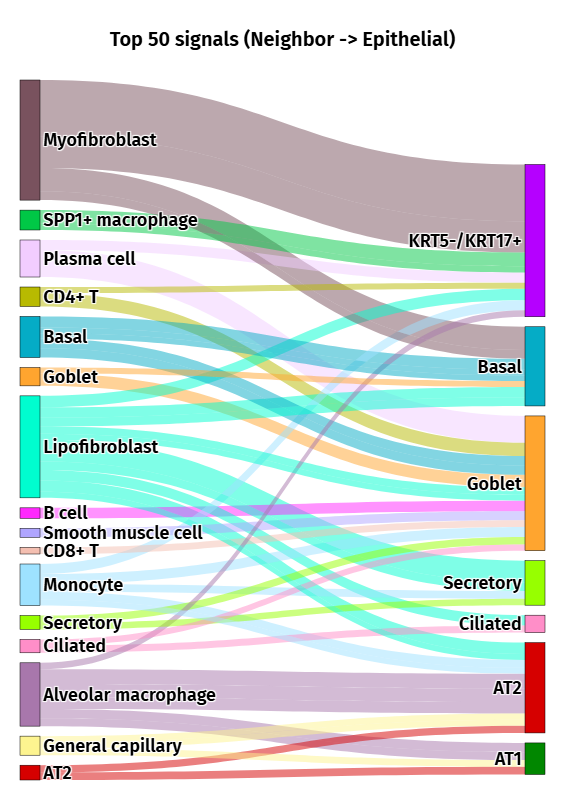

In [7]:
# Sankey diagram nei to int
fig = go.Figure(data=[go.Sankey(
    arrangement="snap",
    node=dict(
        label=sanky_dict[direc[0]]["labels"],
        pad=10,
        thickness=20,
        line=dict(color="black", width=0.5),
        color=sanky_dict[direc[0]]["node_colors"]
    ),
    link=dict(
        source=sanky_dict[direc[0]]["sources"],
        target=sanky_dict[direc[0]]["targets"],
        value=sanky_dict[direc[0]]["values"],
        color=sanky_dict[direc[0]]["link_colors"],
    )
)])
    
fig.update_layout(
    title=dict(text=sanky_dict[direc[0]]["title"], x=0.5, y=0.96, font=dict(size=20)),
    font=dict(
        family="Fira sans",   
        size=16,          
        color="black",
        weight="bold"
    ),
    font_size=18,
    width=sanky_wd, 
    height=sanky_ht,
    margin=dict(l=20, r=20, t=80, b=20) 
)

fig.show()

pio.write_image(fig, sanky_dict[direc[0]]["save_name"], width=sanky_wd, height=sanky_ht)

In [8]:
# Sankey diagram int to nei
fig = go.Figure(data=[go.Sankey(
    arrangement="snap",
    node=dict(
        label=sanky_dict[direc[1]]["labels"],
        pad=10,
        thickness=20,
        line=dict(color="black", width=0.5),
        color=sanky_dict[direc[1]]["node_colors"]
    ),
    link=dict(
        source=sanky_dict[direc[1]]["sources"],
        target=sanky_dict[direc[1]]["targets"],
        value=sanky_dict[direc[1]]["values"],
        color=sanky_dict[direc[1]]["link_colors"],
    )
)])

fig.update_layout(
    title=dict(text=sanky_dict[direc[1]]["title"], x=0.5, y=0.96, font=dict(size=20)),
    font=dict(
        family="Fira sans",   
        size=16,          
        color="black",
        weight="bold"
    ),
    font_size=18,
    width=sanky_wd, 
    height=sanky_ht,
    margin=dict(l=20, r=20, t=80, b=20) 
)

fig.show()

pio.write_image(fig, sanky_dict[direc[1]]["save_name"], width=sanky_wd, height=sanky_ht)

In [9]:
for di in direc:
    sankey_data = sanky_dict[di]

    labels = sankey_data["labels"]
    
    # Source Data作成
    df_source = pd.DataFrame({
        "Source": [labels[int(i)] for i in sankey_data["sources"]],
        "Target": [labels[int(i)] for i in sankey_data["targets"]],
        "Value": sankey_data["values"]
    })
    
    df_source.to_csv(f"{WORK_PATH}CSV/031_sankey_{di}_source_data.csv", index=True)
    

In [10]:
heat_array = []
for d, pm in zip(direc,perm_df_sig):
    top_df_sorted = pm.head(top_n).sort_values(["Source_Subtype", "Target_Subtype", "Obs_norm"])[["Source_Subtype", "Target_Subtype", "Obs_norm", "pathway_name"]]
    source_list = [so for so in ALL_SUBTYPE_LIST if so in top_df_sorted["Source_Subtype"].unique()]
    top_df_sorted.sort_values("Source_Subtype", key = lambda sl: sl.map(source_list.index), inplace=True)
    top_df_sorted["s2t"] =top_df_sorted['Source_Subtype'].str.cat(top_df_sorted['Target_Subtype'], sep=' -> ')
    top_df_sorted["path"] = top_df_sorted['pathway_name'].str.cat(top_df_sorted.index, sep=': ')
    top_df_piv = top_df_sorted.pivot_table(index="s2t", columns="path", values="Obs_norm", sort=False).sort_index(axis='columns')
    
    txt = f"Top {top_n} signals ({d})".replace("nei", "Neighbor").replace("int", f"{interest_label}").replace("_", " ")
    
    heat_data = {
        "s2t":[], # y axis
        "path":[], # x axis
        "value": [],
        "idx": top_df_piv.index, # y label
        "col": top_df_piv.columns,  # x label
        "title": f"{txt.replace("to", "->")}",
        "save_name": f"{WORK_PATH}Figure/031_heat_{txt.replace(" ", "_").replace("(", "").replace(")", "")}.png",
    }
    for r in range(len(top_df_piv.index)):
        for c in range(len(top_df_piv.columns)):
            if top_df_piv.iloc[r,c] > 0:
                heat_data["s2t"].append(c)
                heat_data["path"].append(r)
                heat_data["value"].append(top_df_piv.iloc[r,c])
    heat_array.append(heat_data)

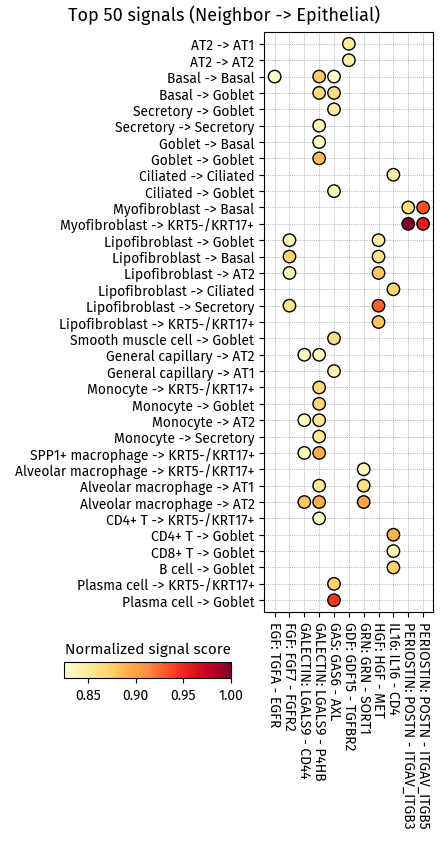

In [11]:
ht_ar = heat_array[0]

# Determine the figure size by the number of indexes and columns
top_bl = 2
c_bl = [10, 1, 1, 3]

rt = [
    1/((max([len(a) for a in ht_ar["idx"]])/2.2)+len(ht_ar["col"])),
    1/((max([len(a) for a in ht_ar["col"]])/2.2)+len(ht_ar["idx"])+top_bl)
]
top_margin = top_bl*rt[1] # right margin, top margin
cl_bar = [c_bl[0]*rt[0], c_bl[1]*rt[1], c_bl[2]*rt[0], c_bl[3]*rt[1]]  # colobar width, height, right margin, and top margin

f_size = [1/(6*rt[0]), 1/(6*rt[1])]

# plotting
fig, ax = plt.subplots(figsize=f_size)
cmap = plt.get_cmap("YlOrRd")

ax.scatter(ht_ar["s2t"], ht_ar["path"], c=ht_ar["value"], cmap=cmap, alpha=1, s=80, vmin=np.min(ht_ar["value"]), edgecolors="black")
ax.set_xticks([n for n in range(len(ht_ar["col"]))])
ax.set_xticklabels(ht_ar["col"], rotation=-90)
ax.set_xlim(-0.7, len(ht_ar["col"])-0.3)

ax.set_yticks([n for n in range(len(ht_ar["idx"]))])
ax.set_yticklabels(ht_ar["idx"])
ax.set_ylim(len(ht_ar["idx"])-0.3, -0.7)

ax.set_axisbelow(True)
ax.grid(color = 'grey', linestyle = ':', linewidth = 0.5)
fig.tight_layout()

cax = fig.add_axes([ax.get_position().x0-cl_bar[0]*1.2, ax.get_position().y0-cl_bar[1]*4, cl_bar[0], cl_bar[1]])
fig.colorbar(matplotlib.cm.ScalarMappable(norm=matplotlib.colors.Normalize(vmin=np.min(ht_ar["value"]), vmax=1), cmap=cmap), cax=cax, orientation='horizontal')
cax.set_title("Normalized signal score", fontsize=11)

title_ax = fig.add_axes([0.5, 1.01-top_margin, 1, top_margin-0.01])
title_ax.axis("off")
title_ax.text(x=0, y=0, s=ht_ar["title"], fontsize=13, ha="center", va="bottom")

fig.subplots_adjust(top=1-top_margin)

fig.savefig(ht_ar["save_name"], dpi=500, format="png", bbox_inches=None)

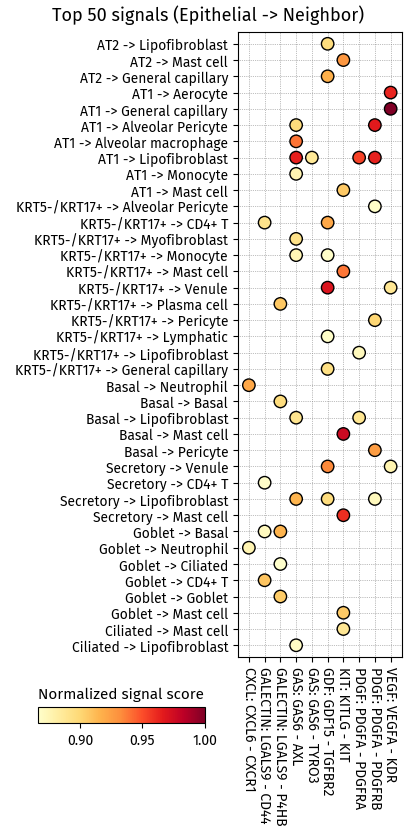

In [12]:
ht_ar = heat_array[1]

# Determine the figure size by the number of indexes and columns
top_bl = 2
c_bl = [10, 1, 1, 3]

rt = [
    1/((max([len(a) for a in ht_ar["idx"]])/2.2)+len(ht_ar["col"])),
    1/((max([len(a) for a in ht_ar["col"]])/2.2)+len(ht_ar["idx"])+top_bl)
]
top_margin = top_bl*rt[1] # right margin, top margin
cl_bar = [c_bl[0]*rt[0], c_bl[1]*rt[1], c_bl[2]*rt[0], c_bl[3]*rt[1]]  # colobar width, height, right margin, and top margin

f_size = [1/(6*rt[0]), 1/(6*rt[1])]

# plotting
fig, ax = plt.subplots(figsize=f_size)
cmap = plt.get_cmap("YlOrRd")

ax.scatter(ht_ar["s2t"], ht_ar["path"], c=ht_ar["value"], cmap=cmap, alpha=1, s=80, vmin=np.min(ht_ar["value"]), edgecolors="black")
ax.set_xticks([n for n in range(len(ht_ar["col"]))])
ax.set_xticklabels(ht_ar["col"], rotation=-90)
ax.set_xlim(-0.7, len(ht_ar["col"])-0.3)

ax.set_yticks([n for n in range(len(ht_ar["idx"]))])
ax.set_yticklabels(ht_ar["idx"])
ax.set_ylim(len(ht_ar["idx"])-0.3, -0.7)

ax.set_axisbelow(True)
ax.grid(color = 'grey', linestyle = ':', linewidth = 0.5)
fig.tight_layout()

cax = fig.add_axes([ax.get_position().x0-cl_bar[0]*1.2, ax.get_position().y0-cl_bar[1]*4, cl_bar[0], cl_bar[1]])
fig.colorbar(matplotlib.cm.ScalarMappable(norm=matplotlib.colors.Normalize(vmin=np.min(ht_ar["value"]), vmax=1), cmap=cmap), cax=cax, orientation='horizontal')
cax.set_title("Normalized signal score", fontsize=11)

title_ax = fig.add_axes([0.5, 1.01-top_margin, 1, top_margin-0.01])
title_ax.axis("off")
title_ax.text(x=0, y=0, s=ht_ar["title"], fontsize=13, ha="center", va="bottom")

fig.subplots_adjust(top=1-top_margin)

fig.savefig(ht_ar["save_name"], dpi=500, format="png", bbox_inches=None)

In [13]:

for ht_ar, di in zip(heat_array, direc):
    df_source = pd.DataFrame({
        "Source_target": [
            ht_ar["col"][int(i)] for i in ht_ar["s2t"]
        ],
        "Interaction": [
            ht_ar["idx"][int(i)] for i in ht_ar["path"]
        ],
        "Normalized_signal_score": ht_ar["value"]
    })
    
    df_source.to_csv(f"{WORK_PATH}CSV/031_heatmap_{di}_source_data.csv", index=True)